# Exercice 1 


In [1]:
## Inverse transform sampling for exponential distribution
import math 
import random 
lam = 2.0
u = random.random()


x = -math.log(1-u)/lam
samples = []
for i in range(10000) : 
    u = random.random()
    samples.append(-math.log(1-u)/lam)
print(sum(samples)/len(samples))



0.49315451138382504


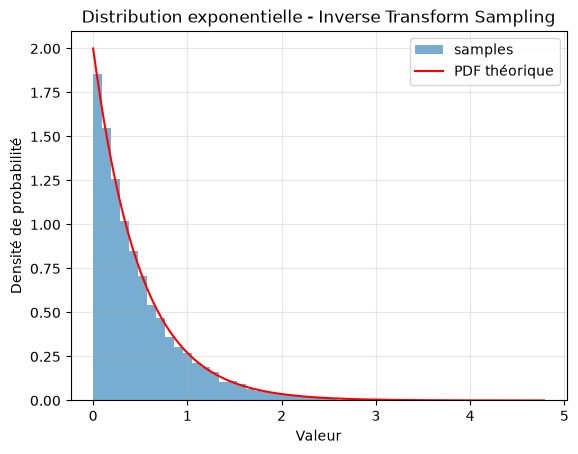

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
plt.hist(samples,bins=50,density=True,alpha=0.6,label="samples")

x =np.linspace(0,max(samples),500)
y  = lam * np.exp(-lam*x)

plt.plot(x,y,color="red", label ="PDF théorique")
plt.xlabel("Valeur")
plt.ylabel("Densité de probabilité")
plt.title("Distribution exponentielle - Inverse Transform Sampling")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Exercice 2 

In [3]:
dice1 = [0.3,0.1,0.1,0.3,0.1,0.1]
dice2 = [0.5,0.1,0.05,0.05,0.2,0.1]

loaded_dice = [[0.0] * 6 for _ in range(6)]

for i in range(len(dice1)) : 
    for j in range(len(dice2)) : 
        loaded_dice[i][j] = dice1[i] * dice2[j]

print(loaded_dice)

[[0.15, 0.03, 0.015, 0.015, 0.06, 0.03], [0.05, 0.010000000000000002, 0.005000000000000001, 0.005000000000000001, 0.020000000000000004, 0.010000000000000002], [0.05, 0.010000000000000002, 0.005000000000000001, 0.005000000000000001, 0.020000000000000004, 0.010000000000000002], [0.15, 0.03, 0.015, 0.015, 0.06, 0.03], [0.05, 0.010000000000000002, 0.005000000000000001, 0.005000000000000001, 0.020000000000000004, 0.010000000000000002], [0.05, 0.010000000000000002, 0.005000000000000001, 0.005000000000000001, 0.020000000000000004, 0.010000000000000002]]


In [6]:
from probability import * 

marginals = joint_to_marginals(loaded_dice)
result = check_independence(loaded_dice,marginals[0], marginals[1])
result 

True

# Exercice 3 

In [18]:
logits_outputs = [2.0,0.5,-1.0,3.0,0.1] ## Correct class index = 3, donc celui avec 3.0
target = 3 
#apply softmax

def custom_softmax(u) :
    shifted = [el - max(u) for el in u]
    exponentials = [math.exp(el) for el in shifted]
    summ =sum(exponentials)
    return [el/summ for el in exponentials]

def custom_ce(u,target_index) : 
    softmaxed = custom_softmax(u)
    res = 0
    for i in range(len(softmaxed)) : 
        factor = 0
        if i == target_index :
            factor=1
        res += factor*math.log(softmaxed[i])
    return -res

custom_ce(logits_outputs,target)




0.42088119968071197

In [19]:
import torch
import torch.nn as nn

logits = torch.tensor([logits_outputs], dtype=torch.float32)
targets = torch.tensor([target])

criterion = nn.CrossEntropyLoss()
torch_loss = criterion(logits, targets)

print("Custom CE :", custom_ce(logits_outputs, target))
print("PyTorch CE:", torch_loss.item())

Custom CE : 0.42088119968071197
PyTorch CE: 0.4208811819553375


# Exercice 4 

In [ ]:
words = [0.01 for _ in range(50)]
raw_summ = sum(words)
log = [math.log(prob) for prob in words]
sentence = sum(log)
sentence_raw = 1

for w in words : 
    sentence_raw = sentence_raw * w

print(f"{words=}")
print(f"{log=}")
print(f"{sentence=}")
print(f"{sentence_raw=}")


words=[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
log=[-4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.605170185988091, -4.60517

-195.6011502714073